In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

print("Toutes les bibliothèques sont installées !")

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)

Toutes les bibliothèques sont installées !
Pandas : 3.1.0
NumPy : 2.5.4
Scikit-learn : 1.9.1


In [3]:
df = sns.load_dataset("titanic")

df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [4]:
print("Dimensions du dataset :", df.shape)

df.info()

Dimensions du dataset : (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [6]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Variables numériques :")
print(numerical_columns.tolist())

Variables numériques :
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


In [7]:
categorical_columns = df.select_dtypes(
    include=["str", "category", "bool"]
).columns

print("Variables catégorielles :")
print(categorical_columns.tolist())

Variables catégorielles :
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [8]:
missing_values = df.isnull().sum()

print("Nombre de valeurs manquantes par colonne :")
print(missing_values)

Nombre de valeurs manquantes par colonne :
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Pourcentage des valeurs manquantes :")
print(missing_percentage.round(2))

Pourcentage des valeurs manquantes :
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


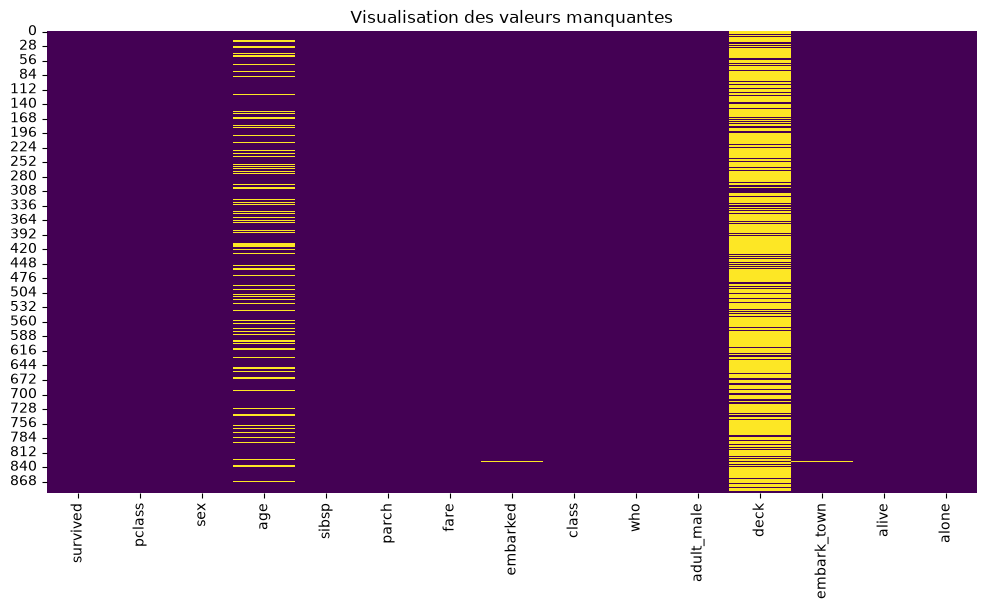

In [10]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Visualisation des valeurs manquantes")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

# Séparation des variables explicatives et de la variable cible
X = df.drop(columns=["survived", "alive"])
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [13]:
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("\nDistribution de y_train :")
print(y_train.value_counts())

print("\nDistribution de y_test :")
print(y_test.value_counts())

Dimensions de X_train : (712, 13)
Dimensions de X_test : (179, 13)

Distribution de y_train :
survived
0    439
1    273
Name: count, dtype: int64

Distribution de y_test :
survived
0    110
1     69
Name: count, dtype: int64


In [14]:
print("Valeurs manquantes dans X_train :")
print(X_train.isnull().sum())

print("\nValeurs manquantes dans X_test :")
print(X_test.isnull().sum())

Valeurs manquantes dans X_train :
pclass           0
sex              0
age            137
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           553
embark_town      2
alone            0
dtype: int64

Valeurs manquantes dans X_test :
pclass           0
sex              0
age             40
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           135
embark_town      0
alone            0
dtype: int64


In [15]:
X_train = X_train.drop(columns=["deck"])
X_test = X_test.drop(columns=["deck"])

In [16]:
age_median = X_train["age"].median()

# Remplacement des valeurs manquantes
X_train["age"] = X_train["age"].fillna(age_median)
X_test["age"] = X_test["age"].fillna(age_median)

print("Médiane de age :", age_median)

Médiane de age : 28.5


In [17]:
embarked_mode = X_train["embarked"].mode()[0]
town_mode = X_train["embark_town"].mode()[0]

X_train["embarked"] = X_train["embarked"].fillna(embarked_mode)
X_test["embarked"] = X_test["embarked"].fillna(embarked_mode)

X_train["embark_town"] = X_train["embark_town"].fillna(town_mode)
X_test["embark_town"] = X_test["embark_town"].fillna(town_mode)

In [18]:
print("Missing Values dans X_train :")
print(X_train.isnull().sum())

print("\nMissing Values dans X_test :")
print(X_test.isnull().sum())

Missing Values dans X_train :
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alone          0
dtype: int64

Missing Values dans X_test :
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alone          0
dtype: int64


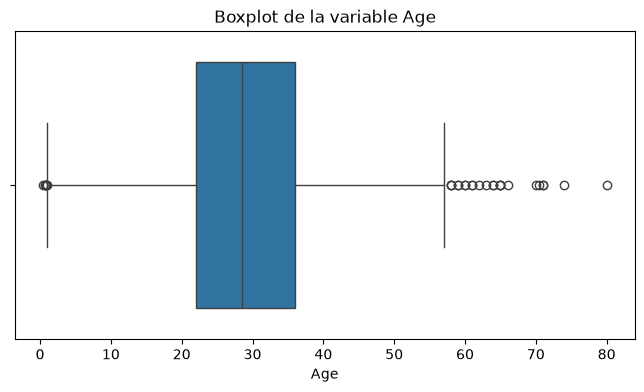

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.boxplot(x=X_train["age"])

plt.title("Boxplot de la variable Age")
plt.xlabel("Age")

plt.show()

In [20]:
Q1 = X_train["age"].quantile(0.25)
Q3 = X_train["age"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Limite inférieure :", lower_bound)
print("Limite supérieure :", upper_bound)

Q1 : 22.0
Q3 : 36.0
IQR : 14.0
Limite inférieure : 1.0
Limite supérieure : 57.0


In [21]:
outliers = X_train[
    (X_train["age"] < lower_bound) |
    (X_train["age"] > upper_bound)
]

print("Nombre d'Outliers :", len(outliers))
print(outliers[["age"]])

Nombre d'Outliers : 29
       age
33   66.00
96   71.00
195  58.00
684  60.00
232  59.00
694  60.00
94   59.00
268  58.00
469   0.75
78    0.83
545  64.00
438  64.00
326  61.00
483  63.00
803   0.42
851  74.00
755   0.67
493  71.00
280  65.00
831   0.83
170  61.00
487  58.00
54   65.00
672  70.00
305   0.92
456  65.00
829  62.00
630  80.00
116  70.50


In [22]:
age_median = X_train["age"].median()

print("Médiane de age :", age_median)

Médiane de age : 28.5


In [24]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

X_train_clean.loc[
    (X_train_clean["age"] < lower_bound) |
    (X_train_clean["age"] > upper_bound),
    "age"
] = age_median


X_test_clean.loc[
    (X_test_clean["age"] < lower_bound) |
    (X_test_clean["age"] > upper_bound),
    "age"
] = age_median

In [25]:
print("Outliers avant traitement :", len(outliers))

remaining = X_train_clean[
    (X_train_clean["age"] < lower_bound) |
    (X_train_clean["age"] > upper_bound)
]

print("Outliers après traitement :", len(remaining))

Outliers avant traitement : 29
Outliers après traitement : 0


In [26]:
print("Variables catégorielles :")

print(
    X_train_clean.select_dtypes(
        include=["object", "category", "bool", "str"]
    ).columns.tolist()
)

Variables catégorielles :
['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alone']


In [27]:
nominal_columns = [
    "sex",
    "embarked",
    "who",
    "embark_town"
]

X_train_encoded = pd.get_dummies(
    X_train_clean,
    columns=nominal_columns,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test_clean,
    columns=nominal_columns,
    dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

In [28]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

print(X_train_encoded.head())

(712, 19)
(179, 19)
     pclass   age  sibsp  parch      fare   class  adult_male  alone  \
692       3  28.5      0      0   56.4958   Third        True   True   
481       2  28.5      0      0    0.0000  Second        True   True   
527       1  28.5      0      0  221.7792   First        True   True   
855       3  18.0      0      1    9.3500   Third       False  False   
801       2  31.0      1      1   26.2500  Second       False  False   

     sex_female  sex_male  embarked_C  embarked_Q  embarked_S  who_child  \
692           0         1           0           0           1          0   
481           0         1           0           0           1          0   
527           0         1           0           0           1          0   
855           1         0           0           0           1          0   
801           1         0           0           0           1          0   

     who_man  who_woman  embark_town_Cherbourg  embark_town_Queenstown  \
692        1    

In [29]:
from sklearn.preprocessing import OrdinalEncoder

categories = [["First", "Second", "Third"]]

encoder = OrdinalEncoder(categories=categories)

X_train_encoded["class_encoded"] = encoder.fit_transform(
    X_train_encoded[["class"]]
)

X_test_encoded["class_encoded"] = encoder.transform(
    X_test_encoded[["class"]]
)

print(X_train_encoded[["class", "class_encoded"]].head(10))

      class  class_encoded
692   Third            2.0
481  Second            1.0
527   First            0.0
855   Third            2.0
801  Second            1.0
652   Third            2.0
509   Third            2.0
557   First            0.0
828   Third            2.0
18    Third            2.0


In [30]:
X_train_encoded["adult_male"] = X_train_encoded["adult_male"].astype(int)
X_test_encoded["adult_male"] = X_test_encoded["adult_male"].astype(int)

X_train_encoded["alone"] = X_train_encoded["alone"].astype(int)
X_test_encoded["alone"] = X_test_encoded["alone"].astype(int)

print(X_train_encoded[["adult_male", "alone"]].head())

     adult_male  alone
692           1      1
481           1      1
527           1      1
855           0      0
801           0      0


In [31]:
X_train_encoded = X_train_encoded.drop(columns=["class"])
X_test_encoded = X_test_encoded.drop(columns=["class"])

print("Colonnes non numériques dans Train :")
print(X_train_encoded.select_dtypes(exclude=np.number).columns.tolist())

print("Colonnes non numériques dans Test :")
print(X_test_encoded.select_dtypes(exclude=np.number).columns.tolist())

Colonnes non numériques dans Train :
[]
Colonnes non numériques dans Test :
[]


In [32]:
from sklearn.preprocessing import MinMaxScaler

scaler_minmax = MinMaxScaler()

X_train_minmax = scaler_minmax.fit_transform(X_train_encoded)
X_test_minmax = scaler_minmax.transform(X_test_encoded)

X_train_minmax = pd.DataFrame(
    X_train_minmax,
    columns=X_train_encoded.columns,
    index=X_train_encoded.index
)

X_test_minmax = pd.DataFrame(
    X_test_minmax,
    columns=X_test_encoded.columns,
    index=X_test_encoded.index
)

print(X_train_minmax.head())

     pclass       age  sibsp     parch      fare  adult_male  alone  \
692     1.0  0.491071  0.000  0.000000  0.110272         1.0    1.0   
481     0.5  0.491071  0.000  0.000000  0.000000         1.0    1.0   
527     0.0  0.491071  0.000  0.000000  0.432884         1.0    1.0   
855     1.0  0.303571  0.000  0.166667  0.018250         0.0    0.0   
801     0.5  0.535714  0.125  0.166667  0.051237         0.0    0.0   

     sex_female  sex_male  embarked_C  embarked_Q  embarked_S  who_child  \
692         0.0       1.0         0.0         0.0         1.0        0.0   
481         0.0       1.0         0.0         0.0         1.0        0.0   
527         0.0       1.0         0.0         0.0         1.0        0.0   
855         1.0       0.0         0.0         0.0         1.0        0.0   
801         1.0       0.0         0.0         0.0         1.0        0.0   

     who_man  who_woman  embark_town_Cherbourg  embark_town_Queenstown  \
692      1.0        0.0                   

In [33]:
from sklearn.preprocessing import StandardScaler

scaler_standard = StandardScaler()

X_train_zscore = scaler_standard.fit_transform(X_train_encoded)
X_test_zscore = scaler_standard.transform(X_test_encoded)

X_train_zscore = pd.DataFrame(
    X_train_zscore,
    columns=X_train_encoded.columns,
    index=X_train_encoded.index
)

X_test_zscore = pd.DataFrame(
    X_test_zscore,
    columns=X_test_encoded.columns,
    index=X_test_encoded.index
)

print(X_train_zscore.head())

       pclass       age     sibsp     parch      fare  adult_male     alone  \
692  0.829568 -0.011427 -0.465084 -0.466183  0.513812    0.814587  0.800346   
481 -0.370945 -0.011427 -0.465084 -0.466183 -0.662563    0.814587  0.800346   
527 -1.571457 -0.011427 -0.465084 -0.466183  3.955399    0.814587  0.800346   
855  0.829568 -0.965934 -0.465084  0.727782 -0.467874   -1.227616 -1.249460   
801 -0.370945  0.215836  0.478335  0.727782 -0.115977   -1.227616 -1.249460   

     sex_female  sex_male  embarked_C  embarked_Q  embarked_S  who_child  \
692   -0.742427  0.742427   -0.492527   -0.289333    0.611978  -0.319636   
481   -0.742427  0.742427   -0.492527   -0.289333    0.611978  -0.319636   
527   -0.742427  0.742427   -0.492527   -0.289333    0.611978  -0.319636   
855    1.346933 -1.346933   -0.492527   -0.289333    0.611978  -0.319636   
801    1.346933 -1.346933   -0.492527   -0.289333    0.611978  -0.319636   

      who_man  who_woman  embark_town_Cherbourg  embark_town_Queenst

In [34]:
print("Mean :")
print(X_train_zscore.mean().round(2))

print("\nStandard Deviation :")
print(X_train_zscore.std(ddof=0).round(2))

Mean :
pclass                    -0.0
age                        0.0
sibsp                     -0.0
parch                     -0.0
fare                      -0.0
adult_male                -0.0
alone                      0.0
sex_female                 0.0
sex_male                  -0.0
embarked_C                -0.0
embarked_Q                -0.0
embarked_S                 0.0
who_child                  0.0
who_man                   -0.0
who_woman                 -0.0
embark_town_Cherbourg     -0.0
embark_town_Queenstown    -0.0
embark_town_Southampton    0.0
class_encoded              0.0
dtype: float64

Standard Deviation :
pclass                     1.0
age                        1.0
sibsp                      1.0
parch                      1.0
fare                       1.0
adult_male                 1.0
alone                      1.0
sex_female                 1.0
sex_male                   1.0
embarked_C                 1.0
embarked_Q                 1.0
embarked_S                

In [35]:
print(y_train.value_counts())
print("\nPourcentages :")
print(y_train.value_counts(normalize=True) * 100)

survived
0    439
1    273
Name: count, dtype: int64

Pourcentages :
survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


In [36]:
from imblearn.under_sampling import RandomUnderSampler

undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_encoded,
    y_train
)

print(y_train_under.value_counts())

survived
0    273
1    273
Name: count, dtype: int64


In [37]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_encoded,
    y_train
)

print(y_train_smote.value_counts())

survived
1    439
0    439
Name: count, dtype: int64


In [38]:
print("Train original :", X_train_encoded.shape)
print("Test original :", X_test_encoded.shape)

print("Train Undersampling :", X_train_under.shape)
print("Train SMOTE :", X_train_smote.shape)
print("Test :", X_test_encoded.shape)

Train original : (712, 19)
Test original : (179, 19)
Train Undersampling : (546, 19)
Train SMOTE : (878, 19)
Test : (179, 19)
